# E131: is Goodfire's new Qwen3-1.7B decomposition more faithful on reasoning text?

**The answer.** Yes under the adversary, not with its own masks. The new decomposition loads and runs in our code, matching the authors' library. On GSM8K solutions written by Qwen itself, VPD's mask adversary pushes the old decomposition about seven times further from the model than the new one, with thinking on or off. With its own causal importance as masks the two are about equally faithful on maths. On web text, which the new one was not trained on, the new one is less faithful with its own masks. It switches on about 30% fewer subcomponents per token.

This is a provisional reading under the fast lane: one adversary seed, 128 rows per row set, no independent check. Report: `reports/analyses/2026-11-07_analysis_e131-new-decomposition.md`. Ten MATS `debug` L40 jobs, $0.


## What we were trying to test

The user was given a second decomposition of Qwen3-1.7B, run p-9707d6ff, said to be more faithful on reasoning tasks. Every Qwen reading so far used the first one, run p-e9fcffd5. Below they are **the new decomposition** and **the old decomposition**. Both write each weight matrix of the model as a sum of rank-one subcomponents, $W \approx \sum_c V_{:,c} U_{c,:}$, and both come with a learned causal importance function Γ that gives each subcomponent a value $g$ between 0 and 1 at every token: 0 means the subcomponent can be dropped there, 1 means it is needed.

The two were trained on different text. The old one saw a text mix called firestock3, in windows of 512 tokens. The new one saw chat-formatted text in windows of 2,048 tokens, 30% of it written by Qwen3-1.7B itself, some in thinking mode.

First we checked the port. The new decomposition's subcomponents rebuild every matrix to the bundle's stated error. Our Γ agrees with the authors' JAX library on 8 rows: about one value in 80,000 differs by more than 0.1. The old decomposition, run through the same new code, reproduced its stored faithfulness number to within 0.01%.

Then both decompositions were read on the same three row sets, each of 128 rows of at most 512 tokens:

- **web text**: the 128 FineWeb rows of the earlier Qwen adversary run, 512 tokens each;
- **maths, thinking off**: the first 128 GSM8K test prompts in Qwen's chat template, followed by Qwen3-1.7B's own greedy answer;
- **maths, thinking on**: the same prompts with thinking on. Thinking traces are long, so 104 of the 128 rows were cut at 512 tokens.

Three numbers were read per row, each a mean over the row's tokens, then averaged over rows:

1. **KL with its own masks**: the KL divergence from the model's next-token distribution to the decomposed model's, when each subcomponent is multiplied by its own $g$ and the residual Δ is left out. 0 means the masked model predicts exactly like the model.
2. **KL under the adversary**: the same KL, but with the masks moved by VPD's evaluation adversary. It starts from random masks and takes 20 sign steps of 0.1 up the KL, with the floor of each mask at $g$. A large number means the decomposition is easy to break. One random start, seed 0, the same for both decompositions.
3. **Active count**: how many subcomponents have $g > 0.1$ at a token, summed over all 196 matrices.

There is no do-nothing reference here: the old decomposition is the reference for the new one, row for row. Each comparison is the ratio of the new mean to the old mean, with a 95% interval from resampling the 128 rows.


## What we expected, and why

The new decomposition was trained on chat text that includes Qwen's own answers, so we expected it to be more faithful than the old one on the two maths row sets, by both KL numbers. Four predictions were filed before the run: on each maths row set, the new mean below the old, with the whole 95% interval of the ratio below 1. Web text and the active count were reported without a prediction. On web text the direction was unclear, since the old decomposition was trained on text like it.


## What we observed

### Is the new decomposition harder for the adversary to break on maths text?


row set                      old       new  new / old  95% interval
web text                   1.734     1.301      0.750  [0.693, 0.808]
maths, thinking off        11.36     1.596      0.141  [0.135, 0.146]
maths, thinking on         6.554     1.002      0.153  [0.149, 0.157]


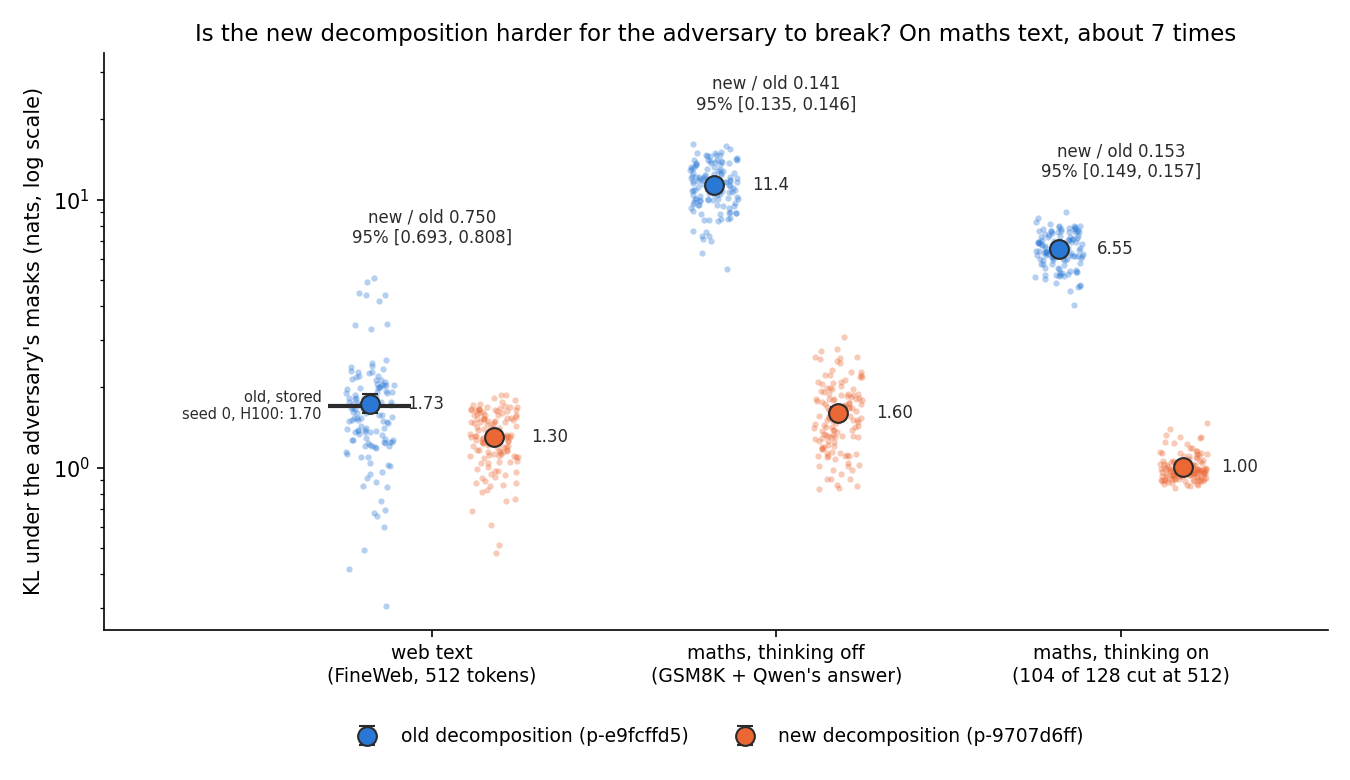

In [1]:
import json
from pathlib import Path

from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
EXP = ROOT / "experiments/qwen_new_decomp"
ratios = json.loads((EXP / "results/score.json").read_text())["ratios"]
NAMES = {"T": "web text", "G": "maths, thinking off", "G-think": "maths, thinking on"}


def table(number: str) -> None:
    print(f"{'row set':22s}{'old':>10s}{'new':>10s}{'new / old':>11s}  95% interval")
    for rows, name in NAMES.items():
        r = ratios[f"{rows}/{number}"]
        print(f"{name:22s}{r['old_mean']:10.4g}{r['new_mean']:10.4g}{r['ratio']:11.3f}  [{r['lo95']:.3f}, {r['hi95']:.3f}]")


table("adv_kl")
display(Image(filename=str(EXP / "figures/adversary.png")))


**Reading it.** Yes, by a wide margin on maths text. The adversary pushes the old decomposition to a KL of 11.4 nats on maths with thinking off and 6.6 with thinking on. The new one stays at 1.6 and 1.0. That is a ratio of 0.14 to 0.15, and every one of the 256 maths rows reads lower on the new decomposition: the clouds do not overlap. On web text the new one is also harder to break, at 1.3 against 1.7, with a fifth of the rows going the other way. The old decomposition's web-text value of 1.73 sits within 2% of the 1.70 the earlier run stored for the same seed on an H100, so the adversary behaves as before. The old decomposition's weakness on maths is large in its own terms too: four to seven times its web-text value. The interval covers the rows only; with one adversary start it says nothing about seed-to-seed spread, which was 19% on web text before.


### Is the new decomposition more faithful with its own masks?


row set                      old       new  new / old  95% interval
web text                  0.1417     0.209      1.475  [1.456, 1.495]
maths, thinking off      0.05706   0.06117      1.072  [1.053, 1.092]
maths, thinking on       0.05981   0.05261      0.880  [0.860, 0.900]


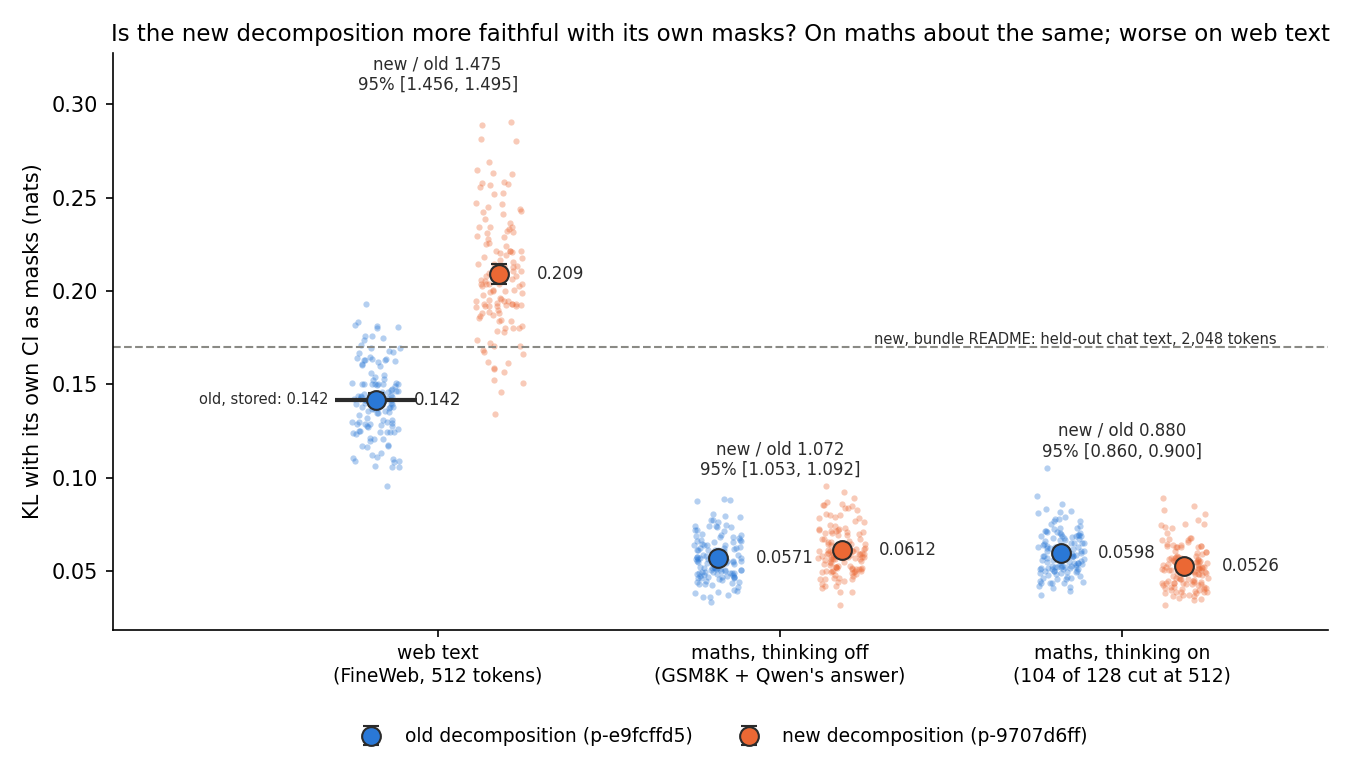

In [2]:
table("ci_kl")
display(Image(filename=str(EXP / "figures/ci_kl.png")))


**Reading it.** Not on maths with thinking off, a little on maths with thinking on, and no on web text. With thinking off the new decomposition reads 0.061 nats against the old one's 0.057, 7% higher, and only 34 of 128 rows are lower on the new one: the filed prediction missed. With thinking on it reads 0.053 against 0.060, 12% lower, with 110 of 128 rows lower. On web text the new one reads 0.209 against 0.142, about half again as much, and higher on every row. The bundle README gives 0.17 for the new decomposition on its own held-out chat text at 2,048 tokens; web text at 512 tokens is outside that training distribution. Both decompositions read far lower on maths than on web text. Part of that is the rows themselves: the maths answers are Qwen's own greedy output, so the model is confident on them and there is less of its distribution to get wrong.


### Does the new decomposition use fewer subcomponents per token?


row set                      old       new  new / old  95% interval
web text                    8403      6197      0.738  [0.736, 0.739]
maths, thinking off         8278      5794      0.700  [0.697, 0.702]
maths, thinking on          8012      5891      0.735  [0.733, 0.738]


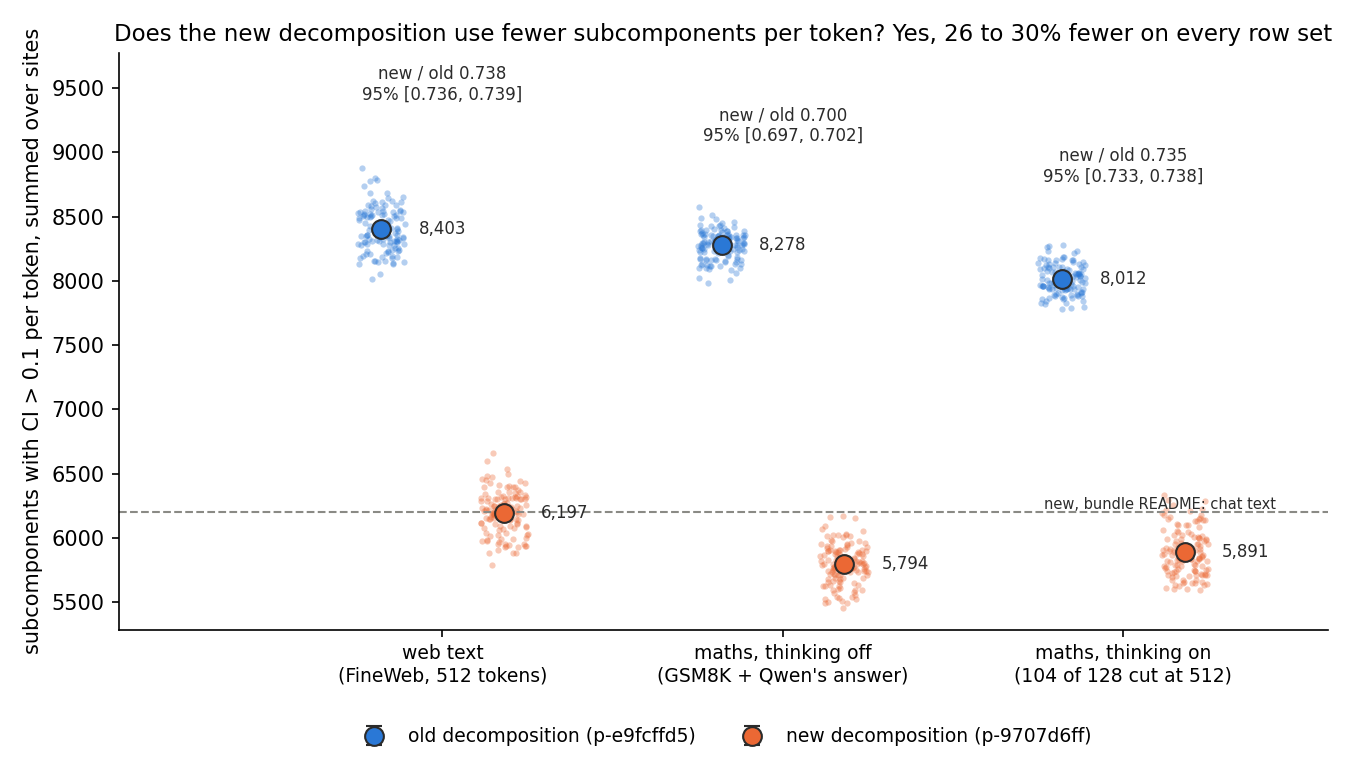

In [3]:
table("active")
display(Image(filename=str(EXP / "figures/active.png")))


**Reading it.** Yes: the new decomposition switches on 26 to 30% fewer subcomponents per token on every row set, about 5,800 to 6,200 against the old one's 8,000 to 8,400, and fewer on every row. On web text it reads 6,197, the same as the bundle README's 6,200 on chat text. Both decompositions have 688,128 subcomponents in all, so the new one explains each token with a sparser set while, on maths, staying as faithful with its own masks.


## What we learned

`GOALS.md` asks whether a decomposition stays interpretable along post-training, and our Qwen updates are fine-tunes on GSM8K. Every reading of such an update rests on the decomposition being faithful on the update's own text. On that text the old decomposition is four to seven times easier for the adversary to break than on web text, and the new one is not. With its own masks the two are about equal on maths, and the new one is sparser. So the new decomposition looks the better base for later Qwen readings on maths text, provisionally, and readings on web text would lose some faithfulness with it.

## How compelling is the evidence

The adversary gap is large and consistent: every maths row, both thinking settings, ratios near 0.15 with narrow intervals. What it rests on is narrow. There was one adversary start, so seed-to-seed spread is not measured. There are 128 rows per set, all from the first 128 GSM8K test prompts. The thinking-on rows are mostly cut at 512 tokens, so they show the start of a thinking trace and rarely its end; the new decomposition was trained at 2,048 tokens and nothing past 512 was read. The KL numbers say how close the masked model's distribution stays, not whether the masked model still solves the problem: no task accuracy was measured with the masks. Web text lies outside the new decomposition's training data, so the web-text readings say how it carries over, not how good it is. None of this says the subcomponents mean anything: the bundle has no labels.

## Surprises

The filed prediction for maths with thinking off missed: the new decomposition is 7% less faithful with its own masks there, not more. Only the adversary separates the two on maths. The size of the old decomposition's weakness on maths was not anticipated either: 11.4 nats against 1.7 on web text.

## What next

- **Move the GSM8K readings to the new decomposition.** A card for the user; the next Qwen reading waits on it. If the user prefers to stay on the old one, nothing below runs.
- **Task accuracy with the masks.** GSM8K answers with each decomposition's own masks. If the new one keeps the answers right and the old one does not, the adversary gap shows up in behaviour too.
- **Three adversary seeds on maths**, if the adversary gap goes into a write-up's answer paragraph: that makes it a headline claim, which needs an independent check.


## Scorecard

Rule for every prediction: the ratio of the new mean to the old mean over the same 128 rows, with a 95% interval from 10,000 row resamples; pass when the ratio and the interval's upper end are both below 1.

| id | claim in words | read: ratio [95% interval] | verdict |
|---|---|---|---|
| P1 | new more faithful with its own masks, maths thinking off | 1.072 [1.053, 1.092] | miss |
| P2 | new more faithful under the adversary, maths thinking off | 0.141 [0.135, 0.146] | pass |
| P3 | new more faithful with its own masks, maths thinking on | 0.880 [0.860, 0.900] | pass |
| P4 | new more faithful under the adversary, maths thinking on | 0.153 [0.149, 0.157] | pass |

Controls before any reading, all passed: the new subcomponents rebuild every matrix within the bundle's 0.0055 relative error, worst 0.00550; our Γ against the JAX library, share of values off by more than 0.1 is 1.2e-5 against a bound of 1e-4; the old decomposition reproduces its stored 0.1417 within 0.01%.

## Not run

- More than one adversary start; seed-to-seed spread on maths.
- Task accuracy on GSM8K with either decomposition's masks.
- Rows past 512 tokens; most thinking traces were cut.
- More than 128 rows per set, or maths outside GSM8K.
- Chat text like the new decomposition's training data, other than the maths rows.
- Any labelling of the new subcomponents.
- An independent check of any number.

## Departures from the literature

- VPD's configured evaluation adversary is used as written, one random start; the earlier Qwen adversary run reported the mean of three starts, 1.62 on web text, of which seed 0 read 1.70.
- The adversary's sources are shared by all rows of a row set, as the config does; per-row values are read at the final sources of that one pooled attack, so the row resampling does not cover seed spread.
- The check of our Γ against the JAX library feeds both the same JAX residual-stream inputs, as the old port's check did; run end to end, the share off by more than 0.1 is 2.5e-5, also under the bound.
- Every row is cut at 512 tokens, the old decomposition's training length, while the new one was trained at 2,048; maths answers were generated in bf16, greedy, in batches of 64.

## Provenance

Results in `experiments/qwen_new_decomp/results/`: `controls.json`, `jax_reference.json`, `rows.json`, `measure_{new,old}_{T,G,G-think}.json`, `score.json`; filed rules in `predictions.json`; code `run.py`, `score.py`, `plot.py`. Plan `reports/plans/2026-11-07_plan_e131-new-decomposition.md`. MATS `debug` L40 jobs 55508 (download), 55531 (conversion), 55532 (JAX reference), 55535 (controls), 55537 to 55542 (one per decomposition and row set), run between 10:32 and 15:56 UTC on 2026-11-07, $0. Code at commit 8f084d29.
